# 試用 LIDA（Gemini 版）

LIDA 的流程：**資料 → 摘要 → 分析目標 → 繪圖程式 → 圖 → 修改／解釋／評分**。
由上往下逐格執行（Shift + Enter）。要換資料、角色或問題，改每格最上面的變數就好。

In [1]:
import os
from dotenv import load_dotenv
load_dotenv()                                   # 讀取同資料夾的 .env（放 API key）

from lida import Manager, TextGenerationConfig
from gemini_textgen import GeminiTextGenerator

MODEL = os.environ.get("GEMINI_MODEL", "gemini-2.5-flash")
lida = Manager(text_gen=GeminiTextGenerator(model=MODEL))
# 想換回 Claude：from claude_textgen import ClaudeTextGenerator，再把上一行換成 ClaudeTextGenerator(model="claude-haiku-5-5")
cfg = TextGenerationConfig(n=1, use_cache=True)  # 快取：同樣的輸入第二次直接回傳，不用重新呼叫
print("使用模型：", MODEL)

使用模型： gemini-3.8-flash


## 1 · 資料 → 摘要（Summarizer）

In [2]:
DATA = "https://raw.githubusercontent.com/uwdata/draco/master/data/cars.csv"
# 也可以換成本機檔案，例如 DATA = "my_data.csv"

summary = lida.summarize(DATA, summary_method="llm", textgen_config=cfg)
print(summary["dataset_description"])
for f in summary["fields"]:
    p = f["properties"]
    print(f"- {f['column']} ({p['dtype']}): {p.get('description', '')}")

A comprehensive dataset of various vehicle models containing technical specifications, performance metrics, dimensions, fuel economy ratings, and pricing information.
- Name (string): Make, model, and trim designation of the vehicle.
- Type (category): Classification or body style category of the vehicle.
- AWD (number): Binary flag indicating whether the vehicle has All-Wheel Drive (1) or not (0).
- RWD (number): Binary flag indicating whether the vehicle has Rear-Wheel Drive (1) or not (0).
- Retail_Price (number): Manufacturer Suggested Retail Price (MSRP) of the vehicle in USD.
- Dealer_Cost (number): Dealer invoice price or wholesale cost of the vehicle in USD.
- Engine_Size__l_ (number): Engine displacement capacity measured in liters.
- Cyl (number): Total number of engine cylinders.
- Horsepower_HP_ (number): Total engine output measured in horsepower (HP).
- City_Miles_Per_Gallon (number): Estimated fuel economy for city driving conditions in miles per gallon (MPG).
- Highway_

## 2 · 角色 → 分析目標（Goal Explorer）

In [3]:
PERSONA = "a college student who wants a cheap car with good gas mileage"

goals = lida.goals(summary, n=3, persona=PERSONA, textgen_config=cfg)
for g in goals:
    display(g)


### Goal 0
---
**Question:** Which vehicle categories and models represent the Pareto-optimal frontier between lowest Retail_Price and highest Highway_Miles_Per_Gallon?

**Visualization:** `Scatter plot of Retail_Price (x-axis) versus Highway_Miles_Per_Gallon (y-axis), colored by vehicle Type, with point size representing Engine_Size__l_ and tooltips showing Name.`

**Rationale:** For a college student prioritizing affordability and long-distance travel efficiency, identifying vehicles in the upper-left quadrant (low Retail_Price and high Highway_Miles_Per_Gallon) is critical. Segmenting by Type and sizing by Engine_Size__l_ reveals whether smaller displacement engines consistently deliver better highway fuel economy within budget-friendly segments or if specific body styles offer superior aerodynamic and cost advantages.



### Goal 1
---
**Question:** How does dealer pricing flexibility (the spread between Retail_Price and Dealer_Cost) vary with City_Miles_Per_Gallon and vehicle Weight?

**Visualization:** `Scatter plot of City_Miles_Per_Gallon (x-axis) versus calculated dealer markup margin (Retail_Price minus Dealer_Cost) (y-axis), colored by vehicle Weight with an overlaid linear regression trend line.`

**Rationale:** College students on strict budgets benefit from knowing how much room dealers have to negotiate on fuel-efficient city commuters. By examining Retail_Price, Dealer_Cost, and City_Miles_Per_Gallon alongside Weight, this visualization demonstrates whether high-efficiency, lightweight cars command rigid retail premiums or if dealers have sufficient margin (Retail_Price - Dealer_Cost) for students to negotiate a substantial discount.



### Goal 2
---
**Question:** What is the penalty on City_Miles_Per_Gallon and Retail_Price when opting for All-Wheel Drive (AWD) across varying Horsepower_HP_ levels?

**Visualization:** `Faceted scatter plot split by AWD (0 vs. 1), showing Horsepower_HP_ (x-axis) versus City_Miles_Per_Gallon (y-axis), with point color mapped to Retail_Price using a continuous color gradient.`

**Rationale:** Students balancing winter weather driving needs against operational running costs need to understand the true trade-off of AWD. Faceting by AWD and plotting Horsepower_HP_ against City_Miles_Per_Gallon while encoding Retail_Price shows how severely all-wheel-drive configurations erode city fuel economy and inflate purchase price for any given engine output level.


## 3 · 問題 → 繪圖程式 → 圖（VizGenerator）
問題請用英文：LIDA 會把問題直接當圖的標題，中文會變方框。

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.
findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


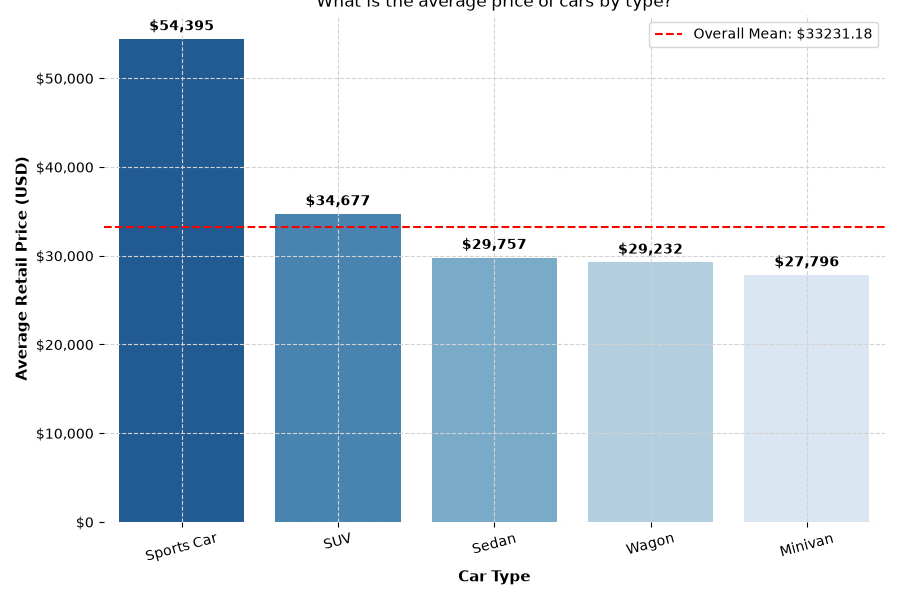

import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# solution plan
# i. Clean the dataset by removing missing values in 'Type' and 'Retail_Price'.
# ii. Compute the average retail price for each vehicle 'Type' and sort descending for optimal presentation.
# iii. Calculate the overall average price across all vehicles to include as a benchmark reference line.
# iv. Use seaborn barplot to display the average price by car type with an appealing color palette.
# v. Add an axhline indicating the overall average price formatted with 0.2f as per requirements.
# vi. Add value labels on each bar, format y-axis as currency, and ensure legible x-axis labels.

def plot(data: pd.DataFrame):
    df_clean = data.dropna(subset=['Type', 'Retail_Price']).copy()
    avg_price = df_clean.groupby('Type', as_index=False)['Retail_Price'].mean()
    avg_price = avg_price.sort_values(by='Retail_Price', ascending=False)
    
    overall_mean = df_clean[

In [4]:
QUESTION = "What is the average price of cars by type?"
# 也可以直接用 LIDA 提的目標：QUESTION = goals[0]

charts = lida.visualize(summary=summary, goal=QUESTION, textgen_config=cfg,
                        library="seaborn", return_error=True)
display(charts[0])
print(charts[0].code)        # 這就是 LIDA 寫出來的程式

## 4 · 用一句話修改（Editor）

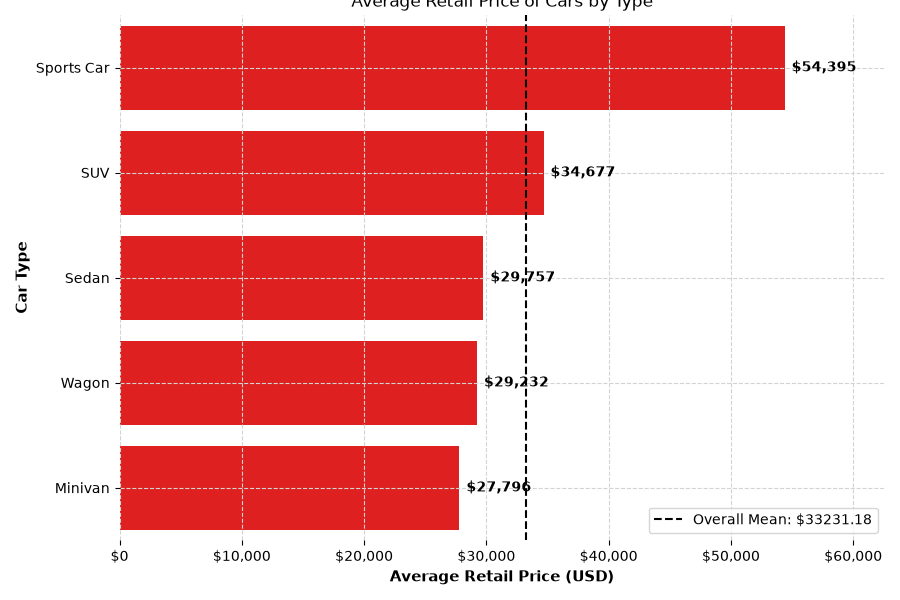

In [5]:
INSTRUCTIONS = ["make it a horizontal bar chart", "make the bars red"]

edited = lida.edit(code=charts[0].code, summary=summary, instructions=INSTRUCTIONS,
                   library="seaborn", textgen_config=cfg, return_error=True)
display(edited[0])

## 5 · 解釋與自我評分（Explainer / Evaluator）

In [6]:
from lida.datamodel import Goal
goal = QUESTION if isinstance(QUESTION, Goal) else Goal(question=QUESTION, visualization=QUESTION, rationale="")

for part in lida.explain(code=edited[0].code, library="seaborn", textgen_config=cfg)[0]:
    print(f"【{part['section']}】{part['explanation']}\n")

for e in lida.evaluate(code=edited[0].code, goal=goal, library="seaborn", textgen_config=cfg)[0]:
    print(f"{e['dimension']:<15} {e['score']}/10  {e['rationale'][:120]}")

【accessibility】The visualization is a horizontal bar chart displaying average retail prices for various car types, sorted in descending order from top to bottom. The bars are colored solid red, accompanied by text labels indicating the precise rounded dollar amount at the end of each bar. A black dashed vertical reference line extends across the plot, highlighting the overall mean retail price. The x-axis is formatted with standard US dollar currency markers, and the background is minimal with top and right spines removed for a clean presentation. The primary goal is to compare average car prices across different categories against the overall market benchmark, making it immediately clear which vehicle types command a premium above the general market average and which are more budget-friendly.

【transformation】This section cleans and prepares the dataset for plotting. First, it removes rows containing missing values in either the 'Type' or 'Retail_Price' columns. It then groups the cle

## 接下來可以試

- **換角色**（第 2 格）：`"an environmental activist worried about pollution"`、`"a car dealer who wants to know which cars sell at the highest price"`
- **換問題**（第 3 格）：`"Is there a relationship between horsepower and fuel efficiency?"`、`"Show everything about this dataset in one chart"`
- **換資料**（第 1 格）：`https://raw.githubusercontent.com/vega/vega-datasets/next/data/seattle-weather.csv`，換完要從第 1 格重跑
- **換模型**：`.env` 裡的 `GEMINI_MODEL` 改成 `gemini-2.5-pro`，然後重新啟動 kernel